# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 7</span>

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 07.1

## Results

In this simulation, particle interactions are evaluated only up to a finite cutoff radius $r_c$ (in Lennard-Jones reduced units), rather than summing over all particle pairs. Truncating the potential at a finite interaction distance introduces a systematic shift in thermodynamic quantities that depend on pair interactions—most notably the potential energy $U$ and the pressure $P$.

To compensate for the omitted long-range interactions beyond $r_c$, we apply explicit **tail corrections**. Assuming a uniform radial distribution function ($g(r) \approx 1$) for distances $r > r_c$, the potential energy tail correction per particle is given by:

$$
\frac{\langle U \rangle_{\text{tail}}}{N} \approx 2\pi \rho \int_{r_c}^{+\infty} \mathrm{d}r \, r^2 V_{\text{LJ}}(r) = 8\pi\rho \left(\frac{1}{9 r_c^9} - \frac{1}{3 r_c^3}\right)
$$

The same principle applies to the pressure, derived from the tail contribution of the virial sum $W = \sum_i \sum_{j < i} \vec{f}_{ij} \cdot \vec{r}_{ij}$. The pressure tail correction is:

$$
 \frac{\langle W \rangle_{\text{tail}}}{3V} \approx -\frac{2\pi}{3}\rho^2 \int_{r_c}^{+\infty} \mathrm{d}r \, r^3 \frac{\mathrm{d}V_{\text{LJ}}(r)}{\mathrm{d}r} = 32\pi\rho^2 \left(\frac{1}{9 r_c^9} - \frac{1}{6 r_c^3}\right)
$$

By adding these analytical terms to the sampled simulation averages, we recover the true bulk thermodynamic behavior of the fluid.

 **Exercise**
 
 In the NSL simulator code we have provided, include tail corrections for potential energy, $U$, and pressure $P$.

# Exercise 07.2

## Results

**Setup.** MC (NVT): $\rho^\star=0.8$, $T^\star=1.1$, $r_c=2.5$, step amplitude $\delta=0.1$, which gives a Metropolis acceptance of about 50%. MD (NVE): $dt^\star=0.001$. Starting from the perfect crystal, part of the initial kinetic energy is converted into potential energy while the lattice melts, so the temperature drops. To end up at $T^\star=1.1$ the MD run was started with $T^\star=1.95$ in `input.dat`: after about 100–200 steps the instantaneous temperature settles around the target value and fluctuates between roughly 0.95 and 1.2.

**Instantaneous $U/N$.** Both simulations start from the crystal value ($U/N \approx -6.7$) and relax within a few hundred steps to a stationary regime, with $U/N$ fluctuating around $\approx -5.45$. The MC signal is noisier because each point is a single sweep of random single-particle moves; the MD signal is smoother because particles move continuously along their trajectories.

**Autocorrelation.** The autocorrelation function of $U/N$ drops very quickly in both cases: for MC it falls below 0.1 after roughly 100 steps, for MD it vanishes after about 50 time steps. Beyond that, the small oscillations  are statistical noise of the estimator. Consecutive values are therefore correlated over $\sim10^2$ steps, so the uncertainty must be computed with blocks  longer than this.

**Data blocking** We can see that after around 1000 steps variance estimates become reliable, on the opposite if we take blocks with less steps we can end up with variances too little for our estimates.



---

 **Exercise**

Use the NSL simulator code to <span style="color:red">print out **instantaneous** values of potential energy per particle, $U/N$, along **equilibrated** Monte Carlo $(N,V,T)$ and Molecular Dynamics $(N,V,E)$ simulations</span> of $M=5\times 10^5$ MC steps or MD time steps (where, for MC, the Metropolis acceptance ratio should be fixed approximately to 50% by changing the value of $dt$ that, in the MC case, represent the amplitude of the step in each direction) in the following thermodynamic conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r^\star_c = 2.5$, for MD $dt^\star=0.001$)

Equilibration is needed both with MC and with MD. With MD, you will observe that starting from a perfect crystalline configuration the temperature, $T$, will not conserve its value. Explore and find the starting value of $T$ needed to stabilize, after a certain number of time steps (equilibration time), the average value of $T$ on the desired $T^\star$.
<span style="color:red">Perform your MC and MD simulations by re-starting after such equilibration time.</span>

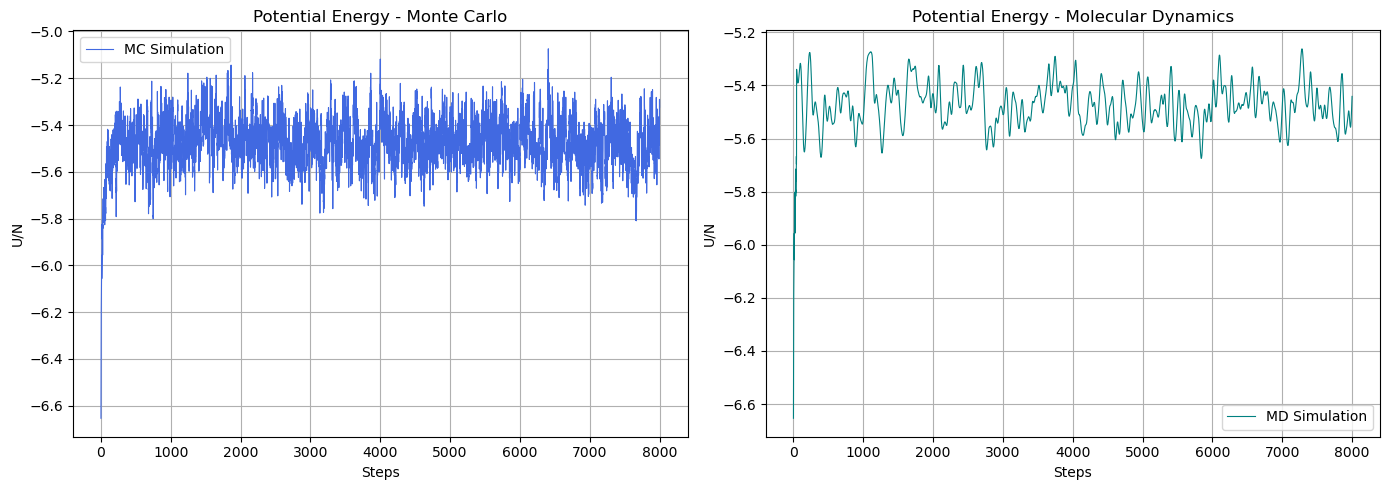

In [77]:
data_mc = np.loadtxt("potential_energy1_MC.dat")
data_md = np.loadtxt("potential_energy2_MD.dat")

x_mc = data_mc[:8000, 0]
mean_mc = data_mc[:8000, 1]

x_md = data_md[:8000, 0]
mean_md = data_md[:8000, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- GRAFICO 1: Monte Carlo (MC) ---
ax1.errorbar(
    x_mc, mean_mc, fmt="-", lw=0.8, color="royalblue", label="MC Simulation"
)
ax1.set_xlabel("Steps")
ax1.set_ylabel("U/N")
ax1.set_title("Potential Energy - Monte Carlo")
ax1.legend()
ax1.grid(True)

# --- GRAFICO 2: Molecular Dynamics (MD) ---
ax2.errorbar(
    x_md, mean_md, fmt="-", lw=0.8, color="teal", label="MD Simulation"
)
ax2.set_xlabel("Steps")
ax2.set_ylabel("U/N")
ax2.set_title("Potential Energy - Molecular Dynamics")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

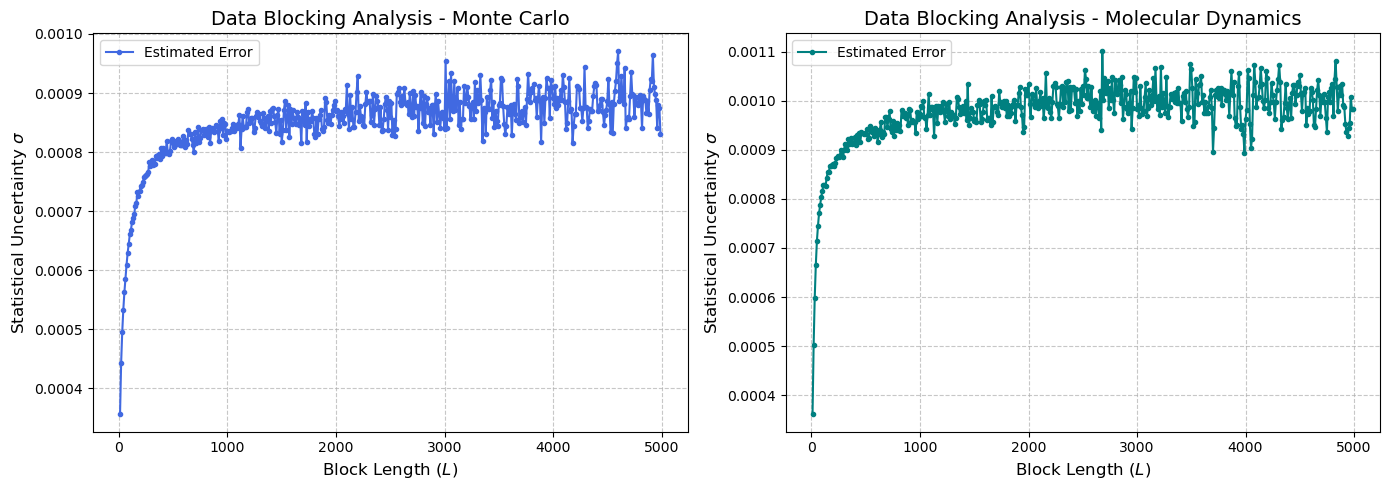

In [73]:
# --- FUNZIONI ---
def error(AV, AV2, n):
    if n <= 0: return 0
    res = (AV2[n] - AV[n]**2) / n
    return math.sqrt(max(0, res))

def blockerror(data, N, L):
    # Estraiamo i blocchi
    ave = np.array([np.mean(data[i*L:(i+1)*L]) for i in range(N)])
    av2 = ave**2
    # Medie progressive
    sum_prog = np.cumsum(ave) / np.arange(1, N+1)
    sum2_prog = np.cumsum(av2) / np.arange(1, N+1)
    return error(sum_prog, sum2_prog, N-1)


# --- DATA LOADING ---
data_mc = np.loadtxt("potential_energy1_MC.dat")[:, 1]
data_md = np.loadtxt("potential_energy2_MD.dat")[:, 1]

sizes = [10 * i for i in range(1, 500)]


# --- ANALYSIS HELPER ---
def compute_block_errors(data):
    errors = []
    valid_sizes = []
    for L in sizes:
        N_blocks = len(data) // L
        if N_blocks > 1:
            err_value = blockerror(data, N_blocks, L)
            errors.append(err_value)
            valid_sizes.append(L)
        else:
            break
    return valid_sizes, errors


sizes_mc, errors_mc = compute_block_errors(data_mc)
sizes_md, errors_md = compute_block_errors(data_md)

# --- PLOTTING SIDE BY SIDE ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- PANEL 1: Monte Carlo ---
ax1.plot(
    sizes_mc,
    errors_mc,
    color="royalblue",
    marker="o",
    ms=3,
    label="Estimated Error",
)
ax1.set_title(r"Data Blocking Analysis - Monte Carlo", fontsize=14)
ax1.set_xlabel(r"Block Length ($L$)", fontsize=12)
ax1.set_ylabel(r"Statistical Uncertainty $\sigma$", fontsize=12)
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend()

# --- PANEL 2: Molecular Dynamics ---
ax2.plot(
    sizes_md,
    errors_md,
    color="teal",
    marker="o",
    ms=3,
    label="Estimated Error",
)
ax2.set_title(r"Data Blocking Analysis - Molecular Dynamics", fontsize=14)
ax2.set_xlabel(r"Block Length ($L$)", fontsize=12)
ax2.set_ylabel(r"Statistical Uncertainty $\sigma$", fontsize=12)
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

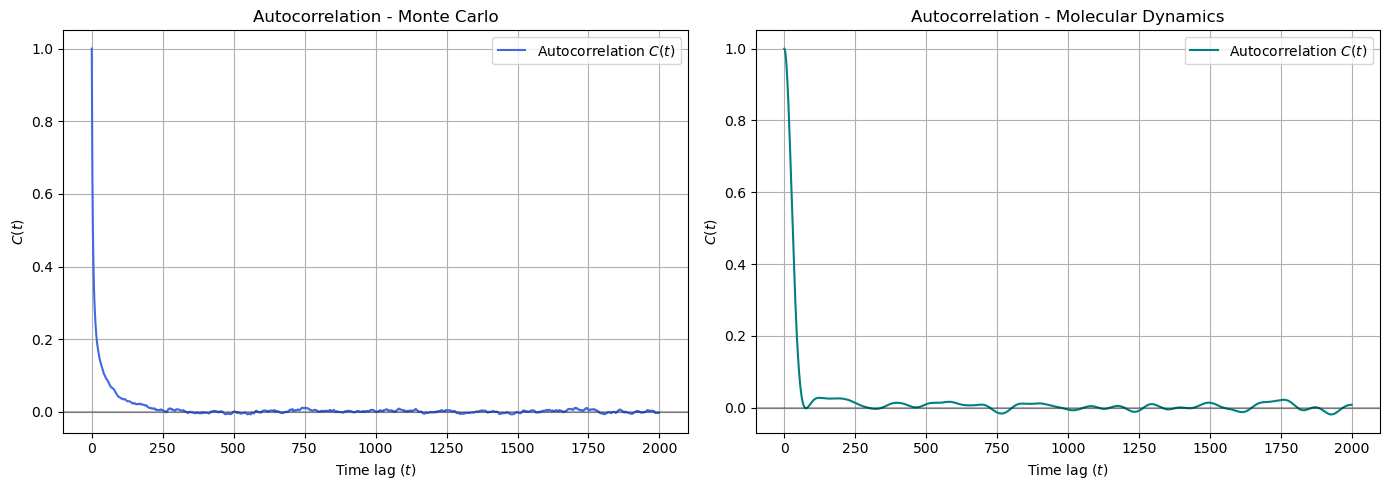

In [75]:
def autocorr(data, t):
  N = len(data)
  mean = np.mean(data)
  var = np.var(data)
  if var == 0 or t >= N:
    return 0
  sum_prod = np.sum((data[: N - t] - mean) * (data[t:] - mean))
  return sum_prod / ((N - t) * var)

# --- DATI ---
data_mc = np.loadtxt("potential_energy1_MC.dat")[:, 1]
data_md = np.loadtxt("potential_energy2_MD.dat")[:, 1]

max_lag = 2000
lags = np.arange(max_lag)

# Calcolo
autocorr_mc = [autocorr(data_mc, t) for t in lags]
autocorr_md = [autocorr(data_md, t) for t in lags]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# MC
ax1.plot(
    lags,
    autocorr_mc,
    color="royalblue",
    linewidth=1.5,
    label="Autocorrelation $C(t)$",
)
ax1.axhline(y=0, color="black", linestyle="-", alpha=0.3)
ax1.set_title("Autocorrelation - Monte Carlo")
ax1.set_xlabel("Time lag ($t$)")
ax1.set_ylabel("$C(t)$")
ax1.legend()
ax1.grid(True)

# MD
ax2.plot(
    lags,
    autocorr_md,
    color="teal",
    linewidth=1.5,
    label="Autocorrelation $C(t)$",
)
ax2.axhline(y=0, color="black", linestyle="-", alpha=0.3)
ax2.set_title("Autocorrelation - Molecular Dynamics")
ax2.set_xlabel("Time lag ($t$)")
ax2.set_ylabel("$C(t)$")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

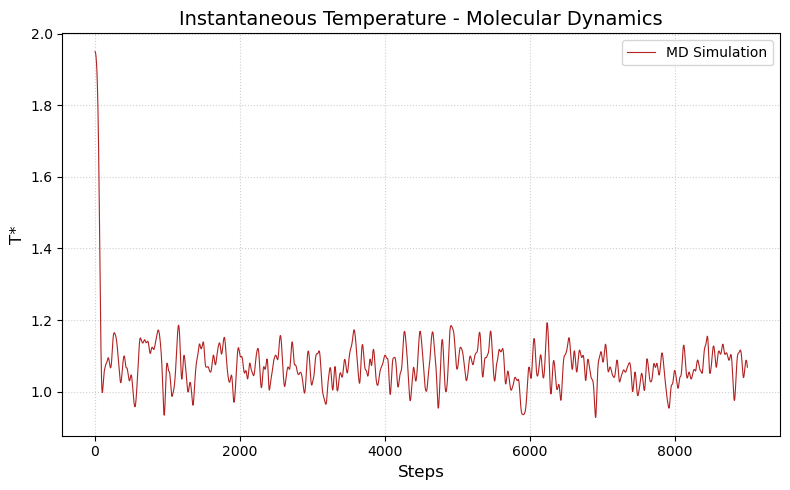

In [36]:
data = np.loadtxt("temperature_MD.dat")

x = data[:, 0]
mean = data[:, 1]

# Setup plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    x, mean, fmt="-", lw=0.8, color="firebrick", label="MD Simulation"
)
ax.set_xlabel("Steps", fontsize=12)
ax.set_ylabel("T*", fontsize=12)
ax.set_title("Instantaneous Temperature - Molecular Dynamics", fontsize=14)
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Exercise 07.3

## Results

To quantify the spatial organisation of the system, we calculate the radial distribution function, $g(r)$, using the following implementation workflow:

1. **Distance Collection & Binning:** 
   Compute all inter-particle distances and aggregate them into discrete histogram bins of width $\Delta r$.
   
2. **Density and Volume Normalisation:** 
   Scale the raw counts to correct for the natural expansion of spherical shell volume at larger radii, as well as the global particle density $\rho$. 

   The scaling factor for each bin is defined as:
   $$\text{Normalization Factor} = \rho N \Delta V(r)$$

   where the shell volume $\Delta V(r)$ corresponds to the geometric difference between two concentric spheres:
   $$\Delta V(r) = \frac{4}{3}\pi \big((r + \Delta r)^3 - r^3\big)$$



---

**Exercise**

<span style="color:red">Include the calculation of the radial distribution function, $g(r)$, as a function of the radial distance $r$ among particles, with $r \in \left[ 0; L/2\right]$ inside the NSL simulator code</span>: average value of $g(r)$ in each block, final average value of $g(r)$ with statistical uncertainties in a separate file.

# Exercise 07.4

## Results

**Setup.** Liquid argon in LJ units: $\rho^\star=0.8$, $T^\star=1.1$, $r_c=2.5$ (including tail corrections).
- MC (NVT): 100 blocks of 2000 steps, $T=1.1$. 
- MD (NVE): 100 blocks of 1000 steps, started with $T=1.95$ in `input.dat` and equilibrated, so that the temperature settles around $T^\star\approx1.1$. The figures show the progressive block averages with their statistical uncertainty.

**MC vs MD.** At the same $(\rho,T)$ the two ensembles give the same structure and the same thermodynamics within a small difference. This is expected for a system of this size, where the NVT and NVE ensembles are equivalent in the thermodynamic limit. The residual gap is most likely due to the fact that in NVE the **temperature is not fixed**: the MD run fluctuates around a mean $\langle T\rangle$ that is slightly different from 1.1 (it is set only by the initial temperature), and a slightly lower temperature gives a slightly lower pressure and potential energy, as observed. **Finite-size effects** ($N$ small) also contribute.

**Radial distribution function.** The $g(r)$ obtained with MC and MD are indistinguishable. They show the typical features of a dense liquid: hard-core repulsion at short distances, a sharp first peak corresponding to the first neighbor shell, a subsequent minimum, a second broad maximum, and a progressive $g \to 1$, since the correlation between two sufficiently distant particles vanishes.

---

**Exercise**

By means of your upgraded NSL simulator code, equilibrate and <span style="color:red">perform MC NVT and MD NVE simulations via a Lennard-Jones model</span> of Argon ($\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r_c = 2.5$)

show in pictures the obtained average values and uncertainties for the potential energy per particle, $U/N$, the pressure $P$ and the radial distribution function $g(r)$ in LJ units ... <span style="color:red"> and compare your MC results for these quantities with those obtained via MD NVE simulations in similar thermodynamic conditions.</span>

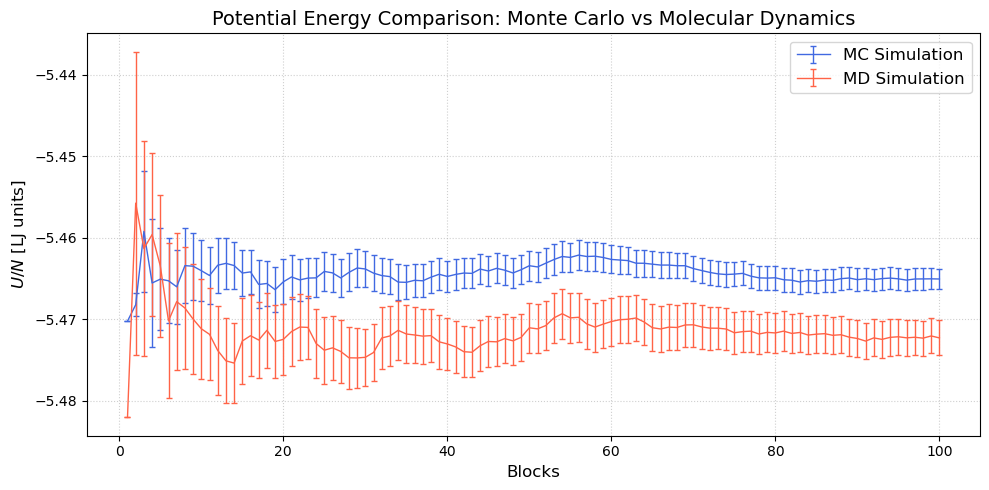

In [6]:
data_mc = np.loadtxt("potential_energy_MC.dat")
data_md = np.loadtxt("potential_energy_MD.dat")


x_mc = data_mc[:, 0]
mean_mc = data_mc[:, 2]
err_mc = data_mc[:, 3]

x_md = data_md[:8000, 0]
mean_md = data_md[:8000, 2]
err_md = data_md[:8000, 3]

# Creazione di un'unica figura condivisa
plt.figure(figsize=(10, 5))

# Plot Monte Carlo con barre d'errore
plt.errorbar(
    x_mc,
    mean_mc,
    yerr=err_mc,
    fmt="-",
    lw=1.0,
    capsize=2,
    color="royalblue",
    label="MC Simulation",
)

# Plot Molecular Dynamics con barre d'errore
plt.errorbar(
    x_md,
    mean_md,
    yerr=err_md,
    fmt="-",
    lw=1.0,
    capsize=2,
    color="tomato",
    label="MD Simulation",
)

plt.xlabel("Blocks", fontsize=12)
plt.ylabel("$U/N$ [LJ units]", fontsize=12)
plt.title(
    "Potential Energy Comparison: Monte Carlo vs Molecular Dynamics", fontsize=14
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

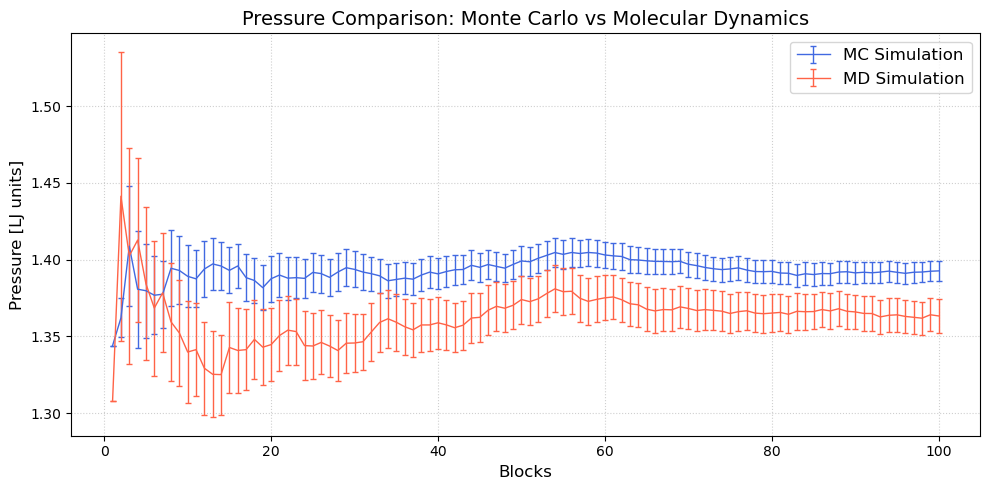

In [8]:
data_mc = np.loadtxt("pressure_MC.dat")
data_md = np.loadtxt("pressure_MD.dat")


x_mc = data_mc[:, 0]
mean_mc = data_mc[:, 2]
err_mc = data_mc[:, 3]

x_md = data_md[:, 0]
mean_md = data_md[:, 2]
err_md = data_md[:, 3]

# Creazione di un'unica figura
plt.figure(figsize=(10, 5))

# Plot Monte Carlo con barre d'errore
plt.errorbar(
    x_mc,
    mean_mc,
    yerr=err_mc,
    fmt="-",
    lw=1.0,
    capsize=2,
    color="royalblue",
    label="MC Simulation",
)

# Plot Molecular Dynamics con barre d'errore
plt.errorbar(
    x_md,
    mean_md,
    yerr=err_md,
    fmt="-",
    lw=1.0,
    capsize=2,
    color="tomato",
    label="MD Simulation",
)

plt.xlabel("Blocks", fontsize=12)
plt.ylabel("Pressure [LJ units]", fontsize=12)
plt.title(
    "Pressure Comparison: Monte Carlo vs Molecular Dynamics", fontsize=14
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

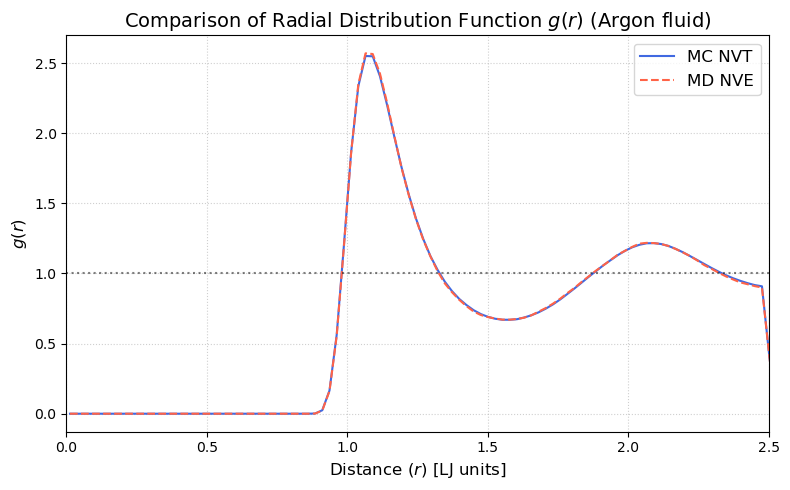

In [62]:
data_mc = np.loadtxt("gofr_MC.dat")
data_md = np.loadtxt("gofr_MD.dat")

plt.figure(figsize=(8, 5))
plt.plot(
    data_mc[:, 0],
    data_mc[:, 1],
    color="royalblue",
    label="MC NVT",
    linewidth=1.5,
)
plt.plot(
    data_md[:, 0],
    data_md[:, 1],
    color="tomato",
    label="MD NVE",
    linestyle="--",
    linewidth=1.5,
)

plt.title(
    "Comparison of Radial Distribution Function $g(r)$ (Argon fluid)", fontsize=14
)
plt.xlabel("Distance ($r$) [LJ units]", fontsize=12)
plt.ylabel("$g(r)$", fontsize=12)
plt.xlim(0, 2.5)
plt.axhline(1, color="black", linestyle=":", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()